# 07a · Phase 1 evaluation: the machine-learning models on the test period

**Objective.** One scored comparison of every non-neural model on the held-out test weeks, with the metrics the brief asks for: **MAE, RMSE and MAPE by forecast horizon**, with **peak versus off-peak** results and uncertainty intervals. It is the Phase 1 counterpart of notebook 07 (which additionally scores the graph networks of Phase 2) and writes `reports/phase1_results_summary.md`.

**Fair-comparison rules (identical for every model).** Same chronological split (the test weeks come strictly after training and validation), same forecast origins and horizons, same equal 60-minute history window, same valid-target mask (a target counts only if it was observed and **every** model produced a finite forecast), forecasts clipped to 0-70 mph, missing readings never treated as zero speed, and the test period never used for fitting, early stopping or tuning.

**Peak / off-peak** was fixed before any model was trained: weekdays 07:00-10:00 and 15:00-19:00, judged on the forecast *target* time.

> Models without a saved prediction file are reported as missing, nothing is invented.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

# Locate the project root (the folder that contains src/config.py) wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
config.ensure_dirs()
print(f"project root : .../{ROOT.name}  (absolute paths are not printed)")
print(f"run mode     : {config.RUN_MODE}" + ("   <-- SMOKE TEST: outputs are NOT final results" if config.IS_SMOKE else ""))

project root : .../T005_MLDL_Project  (absolute paths are not printed)
run mode     : full


In [2]:
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import data_loader as dl, graph_utils as gu, preprocessing as pp, evaluation as ev, visualization as viz

viz.apply_style()
dl.require_raw_files()
ctx = pp.load_context()
N, HZ = len(ctx.sensor_ids), config.HORIZONS
CANDIDATES = ["persistence", "rolling_mean", "seasonal_avg", "random_forest", "xgboost", "xgboost_tuned", "xgboost_spatial"]
preds, y, ymask, origins, horizons, missing = ev.load_aligned(CANDIDATES, "test", ctx.speed, ctx.mask)
MODELS = [m for m in CANDIDATES if m in preds]
assert np.array_equal(origins, ctx.origins["test"]) and horizons == HZ
valid = ev.common_valid_mask({m: preds[m] for m in MODELS}, ymask)
print("models evaluated :", MODELS)
print("not available    :", missing or "none")
print(f"test period      : {ctx.timestamps[ctx.splits.test[0]]} to {ctx.timestamps[ctx.splits.test[1] - 1]}")
print(f"test samples     : {len(origins):,} origins x {len(HZ)} horizons x {N} sensors = {valid.size:,} cells; observed {ymask.mean():.1%}, valid for all models {valid.mean():.1%}")

models evaluated : ['persistence', 'rolling_mean', 'seasonal_avg', 'random_forest', 'xgboost', 'xgboost_tuned', 'xgboost_spatial']
not available    : none
test period      : 2012-06-04 00:00:00 to 2012-06-27 23:55:00
test samples     : 6,901 origins x 4 horizons x 207 sensors = 5,714,028 cells; observed 88.0%, valid for all models 88.0%


## 1 · MAE, RMSE and MAPE by forecast horizon

horizon_min,5,15,30,60
MAE (mph),,,,
Persistence,2.82,3.49,4.19,5.35
Rolling mean (60 min),3.44,3.92,4.55,5.66
Seasonal average,4.18,4.18,4.18,4.18
Random Forest (multi-output),2.41,3.02,3.55,4.14
XGBoost,2.30,2.83,3.25,3.66
XGBoost (tuned),2.30,2.82,3.23,3.61
XGBoost + neighbour features,2.22,2.74,3.16,3.60


horizon_min,5,15,30,60
RMSE (mph),,,,
Persistence,4.61,6.38,7.98,10.25
Rolling mean (60 min),6.52,7.58,8.85,10.80
Seasonal average,7.83,7.83,7.83,7.83
Random Forest (multi-output),4.05,5.47,6.45,7.40
XGBoost,4.04,5.54,6.57,7.44
XGBoost (tuned),4.04,5.52,6.55,7.37
XGBoost + neighbour features,3.81,5.24,6.28,7.21


horizon_min,5,15,30,60
MAPE (%),,,,
Persistence,6.47,8.57,10.79,14.42
Rolling mean (60 min),9.11,10.59,12.55,15.96
Seasonal average,12.97,12.97,12.97,12.97
Random Forest (multi-output),5.89,8.11,10.07,12.32
XGBoost,5.63,7.59,9.47,11.40
XGBoost (tuned),5.62,7.56,9.40,11.14
XGBoost + neighbour features,5.29,7.26,9.06,11.01


valid points scored: 5,026,522


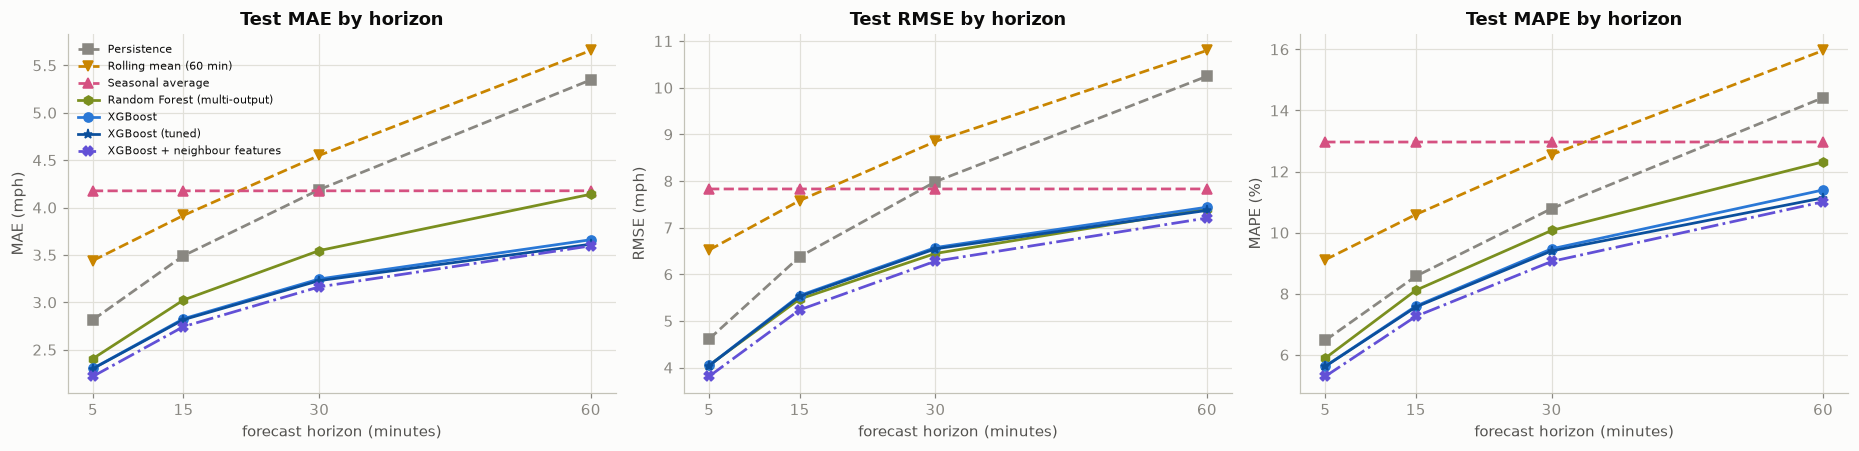

In [3]:
table = ev.metrics_by_horizon({m: preds[m] for m in MODELS}, y, valid, HZ)
table.to_csv(config.METRICS_DIR / f"{config.tagged('phase1_test_metrics')}.csv", index=False)
labels = {m: viz.style(m)["label"] for m in MODELS}
for metric in ("MAE", "RMSE", "MAPE"):
    display(table.pivot(index="model", columns="horizon_min", values=metric).loc[MODELS].rename(index=labels).round(2).rename_axis(f"{metric} ({'%' if metric == 'MAPE' else 'mph'})"))
print(f"valid points scored: {int(valid.sum()):,}")
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, metric in zip(axes, ("MAE", "RMSE", "MAPE")):
    viz.plot_metric_vs_horizon(ax, table, metric, MODELS, title=f"Test {metric} by horizon")
axes[0].legend(fontsize=7); [a.get_legend().remove() for a in axes[1:] if a.get_legend()]
fig.tight_layout(); viz.save_figure(fig, "07a_test_metrics_by_horizon"); plt.show()

## 2 · Uncertainty: day-block bootstrap of the improvements

Whole test days are resampled (errors within a day are strongly correlated). `improvement = 100 x (reference - candidate) / reference`; positive means the candidate has the lower MAE.

In [4]:
target_time = ctx.timestamps.values[origins[:, None] + np.array(HZ)[None, :]]
day_index = ((pd.DatetimeIndex(target_time.ravel()).normalize() - pd.Timestamp(ctx.timestamps[ctx.splits.test[0]]).normalize()).days.to_numpy()).reshape(target_time.shape)

def improvement_with_ci(reference, candidate, metric="MAE", flag=None, n_boot=2000):
    rows = []
    for j, h in enumerate(HZ):
        v = valid[:, j] if flag is None else valid[:, j] & flag[:, j, None]
        o = ev.day_block_bootstrap_improvement(preds[reference][:, j], preds[candidate][:, j], y[:, j], v, day_index[:, j], n_boot=n_boot, metric=metric)
        rows.append({"horizon_min": h * 5, "improvement_%": o["improvement_pct"], "95% CI low": o["ci_low"], "95% CI high": o["ci_high"]})
    return pd.DataFrame(rows).set_index("horizon_min")

PAIRS = [("persistence", "xgboost"), ("xgboost", "random_forest"), ("xgboost", "xgboost_spatial"), ("random_forest", "xgboost_spatial"), ("xgboost", "xgboost_tuned")]
PAIRS = [(a, b) for a, b in PAIRS if a in MODELS and b in MODELS]
imp = {}
for ref, cand in PAIRS:
    imp[(ref, cand)] = improvement_with_ci(ref, cand)
    print(f"\n{labels[cand]} vs {labels[ref]}  (MAE improvement, %)")
    display(imp[(ref, cand)].round(2))
if imp:
    pd.concat({f"{c}_vs_{r}": t for (r, c), t in imp.items()}).to_csv(config.METRICS_DIR / f"{config.tagged('phase1_improvements')}.csv")


XGBoost vs Persistence  (MAE improvement, %)


,improvement_%,95% CI low,95% CI high
horizon_min,,,
5,18.23,17.68,18.75
15,19.05,18.39,19.65
30,22.51,21.38,23.49
60,31.54,29.32,33.32



Random Forest (multi-output) vs XGBoost  (MAE improvement, %)


,improvement_%,95% CI low,95% CI high
horizon_min,,,
5,-4.51,-4.87,-4.24
15,-7.00,-7.56,-6.56
30,-9.24,-10.14,-8.48
60,-13.11,-14.46,-11.81



XGBoost + neighbour features vs XGBoost  (MAE improvement, %)


,improvement_%,95% CI low,95% CI high
horizon_min,,,
5,3.63,3.30,3.96
15,2.94,2.67,3.21
30,2.56,2.22,2.90
60,1.77,1.40,2.16



XGBoost + neighbour features vs Random Forest (multi-output)  (MAE improvement, %)


,improvement_%,95% CI low,95% CI high
horizon_min,,,
5,7.79,7.54,8.04
15,9.29,8.95,9.68
30,10.80,10.29,11.43
60,13.16,12.32,14.09



XGBoost (tuned) vs XGBoost  (MAE improvement, %)


,improvement_%,95% CI low,95% CI high
horizon_min,,,
5,0.09,0.06,0.12
15,0.33,0.28,0.38
30,0.52,0.41,0.63
60,1.30,1.05,1.51


## 3 · Peak versus off-peak

share of valid test points: {'peak': '23.3%', 'off-peak': '76.7%'}


horizon_min,5,15,30,60
"MAE (mph), peak",,,,
Persistence,3.31,4.59,5.82,7.74
Rolling mean (60 min),4.91,5.73,6.76,8.39
Seasonal average,6.52,6.52,6.52,6.52
Random Forest (multi-output),3.05,4.25,5.25,6.42
XGBoost,2.92,3.98,4.83,5.67
XGBoost (tuned),2.92,3.96,4.79,5.55
XGBoost + neighbour features,2.74,3.79,4.63,5.50


horizon_min,5,15,30,60
"MAE (mph), off-peak",,,,
Persistence,2.66,3.16,3.69,4.62
Rolling mean (60 min),2.99,3.37,3.88,4.83
Seasonal average,3.46,3.46,3.46,3.46
Random Forest (multi-output),2.21,2.65,3.03,3.45
XGBoost,2.11,2.48,2.76,3.05
XGBoost (tuned),2.11,2.47,2.75,3.02
XGBoost + neighbour features,2.06,2.42,2.72,3.02


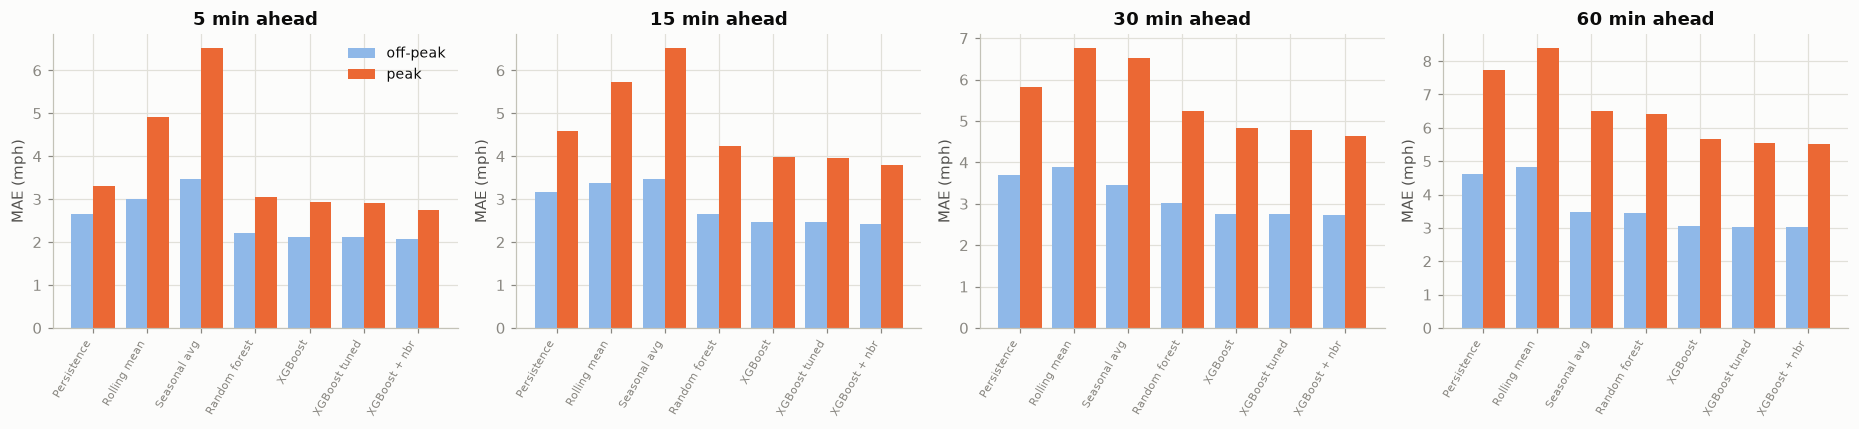

XGBoost MAE improvement over persistence (%), by period:


horizon_min,5,15,30,60
peak,11.8,13.3,17.0,26.8
off-peak,20.7,21.6,25.2,34.0


In [5]:
peak = ev.peak_flags_sh(ctx.timestamps, origins, HZ)
groups = {"peak": peak, "off-peak": ~peak}
grp = ev.metrics_by_group({m: preds[m] for m in MODELS}, y, valid, HZ, groups)
grp.to_csv(config.METRICS_DIR / f"{config.tagged('phase1_test_metrics_peak_offpeak')}.csv", index=False)
share = {g: float((valid & f[:, :, None]).sum() / valid.sum()) for g, f in groups.items()}
print("share of valid test points:", {k: f"{v:.1%}" for k, v in share.items()})
for g in groups:
    display(grp[grp.group == g].pivot(index="model", columns="horizon_min", values="MAE").loc[MODELS].rename(index=labels).round(2).rename_axis(f"MAE (mph), {g}"))
SHORT = {"persistence": "Persistence", "rolling_mean": "Rolling mean", "seasonal_avg": "Seasonal avg", "random_forest": "Random forest",
         "xgboost": "XGBoost", "xgboost_tuned": "XGBoost tuned", "xgboost_spatial": "XGBoost + nbr"}
fig, axes = plt.subplots(1, 4, figsize=(17, 4), sharey=False)
for ax, j in zip(axes, range(len(HZ))):
    sub = grp[grp.horizon_steps == HZ[j]].pivot(index="model", columns="group", values="MAE").loc[MODELS]
    x = np.arange(len(MODELS)); ax.bar(x - 0.2, sub["off-peak"], 0.4, label="off-peak", color="#8fb8e8"); ax.bar(x + 0.2, sub["peak"], 0.4, label="peak", color="#eb6834")
    ax.set_xticks(x); ax.set_xticklabels([SHORT.get(m, labels[m]) for m in MODELS], rotation=60, ha="right", fontsize=7)
    ax.set_title(f"{HZ[j] * 5} min ahead"); ax.set_ylabel("MAE (mph)")
axes[0].legend(); fig.tight_layout(); viz.save_figure(fig, "07a_peak_vs_offpeak"); plt.show()
if "xgboost" in MODELS and "persistence" in MODELS:
    rows = []
    for g, f in groups.items():
        ci = improvement_with_ci("persistence", "xgboost", flag=f, n_boot=1000)
        rows.append(ci["improvement_%"].rename(g))
    print("XGBoost MAE improvement over persistence (%), by period:"); display(pd.concat(rows, axis=1).T.round(1))

## 4 · Where does the error come from?

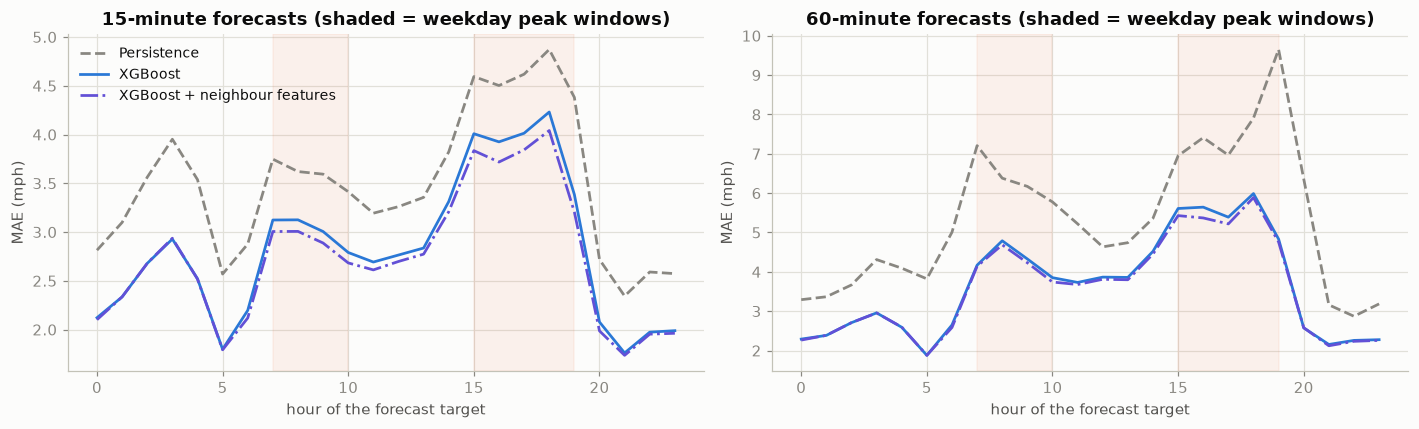

five hardest sensors for XGBoost + neighbour features at 30 minutes:


,sensor_id,MAE,RMSE,n_valid
246,773939,6.49,12.63,6228
154,718045,6.37,11.17,5920
654,717462,6.23,12.26,6232
638,717466,6.20,11.38,6231
102,716960,6.14,9.49,5956


In [6]:
best = "xgboost_spatial" if "xgboost_spatial" in MODELS else "xgboost"
hour = pd.DatetimeIndex(target_time.ravel()).hour.to_numpy().reshape(target_time.shape)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, j in zip(axes, (1, 3)):
    for m in ("persistence", "xgboost", best):
        e = np.abs(preds[m][:, j] - y[:, j]); v = valid[:, j]
        mae_h = [float(e[(hour[:, j] == hh)[:, None] & v].mean()) for hh in range(24)]
        ax.plot(range(24), mae_h, label=labels[m], color=viz.style(m)["color"], ls=viz.style(m)["ls"])
    ax.axvspan(7, 10, color="#eb6834", alpha=0.08); ax.axvspan(15, 19, color="#eb6834", alpha=0.08)
    ax.set_xlabel("hour of the forecast target"); ax.set_ylabel("MAE (mph)"); ax.set_title(f"{HZ[j] * 5}-minute forecasts (shaded = weekday peak windows)")
axes[0].legend(); fig.tight_layout(); viz.save_figure(fig, "07a_error_by_hour"); plt.show()
sens = ev.per_sensor_metrics(preds[best], y, valid, HZ, ctx.sensor_ids)
worst = sens[sens.horizon_steps == HZ[2]].sort_values("MAE", ascending=False).head(5)[["sensor_id", "MAE", "RMSE", "n_valid"]]
print(f"five hardest sensors for {labels[best]} at 30 minutes:"); display(worst.round(2))

## 5 · Write the Phase 1 results summary

In [7]:
FINDINGS = '''**Findings (test period, 24 days, single training run per model; the improvement intervals cover day-to-day variation only).**

1. **Learned models versus naive references.** XGBoost lowers the test MAE by about 18% (5 min) to 32% (60 min) relative to persistence, with 95% intervals that stay far from zero. The seasonal average ignores the current state: it is worse than persistence at 5 and 15 minutes, roughly equal at 30 and better at 60 minutes, but it is worse than XGBoost at every horizon, and the random forest beats it only marginally at 60 minutes.
2. **Boosting versus bagging.** The random forest (settings chosen on validation, see notebook 05c) has a 4.5% (5 min) to 13.1% (60 min) higher MAE than XGBoost, with intervals that exclude zero. Its RMSE, however, is equal to or slightly lower than XGBoost's from 15 minutes on (15 min 5.47 vs 5.54, 30 min 6.45 vs 6.57, 60 min 7.40 vs 7.44 mph; 5 min 4.05 vs 4.04). This is consistent with the training objectives, which were not changed to test the explanation: the forest minimises squared error (a conditional-mean target, which favours RMSE), whereas XGBoost minimises absolute error (a conditional-median target, which favours MAE and MAPE). Which model is better therefore depends on the metric.
3. **Hyper-parameter search.** The configuration adopted by the pre-registered rule (rolling-origin cross-validation, +0.5% threshold) improves the test MAE by only 0.1% (5 min) to 1.3% (60 min). The default configuration was already close to the best of the searched grid; tuning does not change any conclusion.
4. **Road-graph information helps a tree model, most at short horizons and in peak hours.** Adding upstream/downstream neighbour speeds as features lowers the MAE of XGBoost by 3.6% (5 min) to 1.8% (60 min) and its RMSE by 5.7% to 3.1%, with intervals that exclude zero. The gain is larger in peak hours (5 min: 2.92 to 2.74 mph) than off-peak (2.11 to 2.06 mph). XGBoost with neighbour features is therefore the strongest Phase 1 model on every metric (MAE, RMSE, MAPE) and every horizon, and it is the reference a graph neural network has to beat.
5. **Peak versus off-peak.** Every model makes larger absolute errors in the weekday peaks (XGBoost, 5 min: 2.92 vs 2.11 mph; 60 min: 5.67 vs 3.05 mph) and gains less over persistence in relative terms there (about 12% vs 21% at 5 minutes, 27% vs 34% at 60 minutes).
6. **What is not established.** The tree models were fitted once (XGBoost is deterministic; the forest and the tuned model use fixed seeds), the 24 test days contain more missing data than training, and all results concern one city over 119 days. The causal reading of the feature importances is not claimed, and the feature ablation in notebook 05e is cumulative and validation-only, so its stage order matters.'''

def md_table(df, digits=2):
    d = df.copy(); d.columns = [str(c) for c in d.columns]
    head = "| " + " | ".join([d.index.name or ""] + list(d.columns)) + " |\n|" + "---|" * (len(d.columns) + 1)
    body = "\n".join("| " + " | ".join([str(i)] + [f"{v:.{digits}f}" if isinstance(v, (int, float, np.floating)) else str(v) for v in r]) + " |" for i, r in d.iterrows())
    return head + "\n" + body

parts = ["# Phase 1 results summary (machine-learning models)", "",
         f"*Generated by `notebooks/07a_phase1_ml_evaluation.ipynb` from the saved predictions; run mode: **{config.RUN_MODE}**. Every number was computed by that notebook.*", "",
         "## What was and was not run", "",
         f"* Models scored: {', '.join(labels[m] for m in MODELS)}." + (f" Missing (no prediction file): {', '.join(missing)}." if missing else ""),
         f"* Test period: {ctx.timestamps[ctx.splits.test[0]]} to {ctx.timestamps[ctx.splits.test[1] - 1]}; {len(origins):,} forecast origins x {N} sensors x {len(HZ)} horizons; {int(valid.sum()):,} valid points scored ({ymask.mean():.1%} of target cells observed; cells missing for any model are excluded for all).",
         "* Not part of this summary: the graph-based neural models and the signal-control simulation (Phase 2).", ""]
for metric, unit in (("MAE", "mph"), ("RMSE", "mph"), ("MAPE", "%")):
    parts += [f"## Test {metric} ({unit}) by horizon", "", md_table(table.pivot(index="model", columns="horizon_min", values=metric).loc[MODELS].rename(index=labels).rename_axis("model").rename(columns=lambda c: f"{c} min")), ""]
parts += ["## Peak versus off-peak (MAE, mph)", "", f"Peak = weekdays {config.PEAK_WINDOWS} local time of the forecast target; share of valid points: peak {share['peak']:.1%}, off-peak {share['off-peak']:.1%}.", ""]
for g in groups:
    parts += [f"**{g}**", "", md_table(grp[grp.group == g].pivot(index="model", columns="horizon_min", values="MAE").loc[MODELS].rename(index=labels).rename_axis("model").rename(columns=lambda c: f"{c} min")), ""]
parts += ["## MAE improvement with 95% day-block bootstrap interval (positive = candidate is better)", ""]
for (ref, cand), t in imp.items():
    parts += [f"**{labels[cand]} vs {labels[ref]}**", "", md_table(t.rename(columns={"improvement_%": "improvement %"}).rename_axis("horizon (min)")), ""]
parts += ["## Findings", "", FINDINGS, ""]
(config.REPORTS_DIR / "phase1_results_summary.md").write_text("\n".join(parts))
print("written:", (config.REPORTS_DIR / "phase1_results_summary.md").relative_to(ROOT))

written: reports/phase1_results_summary.md
